In [4]:
# Cell 1
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "outputs" / "extracted_entities" / "architecture_knowledge.json"
CHUNKER_PATH = PROJECT_ROOT / "src" / "chunking" / "architecture_chunker.py"
RETRIEVER_PATH = PROJECT_ROOT / "src" / "retrieval" / "retriever.py"
RESULTS_DIR = PROJECT_ROOT / "eval" / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Architecture data exists:", DATA_PATH.exists())
print("Chunker exists:", CHUNKER_PATH.exists())
print("Retriever exists:", RETRIEVER_PATH.exists())
print("Results directory:", RESULTS_DIR)

Project root: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant
Architecture data exists: True
Chunker exists: True
Retriever exists: True
Results directory: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results


In [5]:
# Cell 2
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Architecture data not found: {DATA_PATH}")

with open(DATA_PATH, "r", encoding="utf-8") as file:
    architecture_data = json.load(file)

print("Loaded architecture knowledge.")
print("Top-level type:", type(architecture_data).__name__)

if isinstance(architecture_data, dict):
    print("Top-level keys:", list(architecture_data.keys()))
elif isinstance(architecture_data, list):
    print("Number of records:", len(architecture_data))

Loaded architecture knowledge.
Top-level type: dict
Top-level keys: ['document', 'components', 'ports', 'interfaces', 'data_flows', 'functional_flows', 'dependencies', 'architecture_relationships']


In [6]:
# Cell 3
if isinstance(architecture_data, dict):
    entity_categories = {
        key: len(value)
        for key, value in architecture_data.items()
        if isinstance(value, list)
    }

    category_df = pd.DataFrame(
        entity_categories.items(),
        columns=["Entity Category", "Record Count"]
    )

    display(category_df)
    print("Total records across list categories:", category_df["Record Count"].sum())
else:
    print("The JSON root is a list.")
    print("Record count:", len(architecture_data))
    display(pd.DataFrame(architecture_data).head())

,Entity Category,Record Count
0,components,3
1,ports,7
2,interfaces,3
3,data_flows,5
4,functional_flows,6
5,dependencies,3
6,architecture_relationships,3


Total records across list categories: 30


In [7]:
# Cell 4
if CHUNKER_PATH.exists():
    chunker_source = CHUNKER_PATH.read_text(encoding="utf-8")
    print("CHUNKER SOURCE")
    print("=" * 60)
    print(chunker_source)
else:
    print("Chunker file not found:", CHUNKER_PATH)

CHUNKER SOURCE
# src/chunking/architecture_chunker.py

from pathlib import Path
import json


class ArchitectureChunker:
    """
    Converts extracted AUTOSAR architecture knowledge
    into RAG-ready chunks while preserving
    complete architecture metadata.
    """

    def __init__(self, architecture_data):
        self.architecture_data = architecture_data

    def _create_chunk(
        self,
        content,
        entity_type,
        metadata
    ):
        """
        Create a chunk while preserving all
        architecture-specific metadata.
        """

        chunk_metadata = dict(metadata)

        chunk_metadata["entity_type"] = (
            entity_type
        )

        return {
            "content": content.strip(),
            "metadata": chunk_metadata
        }

    def create_chunks(self):
        """
        Create searchable chunks from all
        extracted architecture entities.
        """

        chunks = []

        self._chunk_components(chunks)
    

In [8]:
# Cell 5
if RETRIEVER_PATH.exists():
    retriever_source = RETRIEVER_PATH.read_text(encoding="utf-8")
    print("RETRIEVER SOURCE")
    print("=" * 60)
    print(retriever_source)
else:
    print("Retriever file not found:", RETRIEVER_PATH)

RETRIEVER SOURCE
# src/retrieval/retriever.py

from pathlib import Path
import json
import re

import faiss
import numpy as np

from src.embeddings.embedder import ArchitectureEmbedder


class ArchitectureRetriever:
    """
    Hybrid retrieval over AUTOSAR architecture knowledge.

    Supports:
    1. Semantic retrieval using FastEmbed + FAISS
    2. Structured architecture-aware retrieval
    3. Hybrid retrieval
    4. Both legacy and production RAG document formats
    """

    def __init__(
        self,
        model_name="BAAI/bge-small-en-v1.5"
    ):

        self.embedder = ArchitectureEmbedder(
            model_name=model_name
        )

        self.chunks = []
        self.index = None

    # =========================================================
    # NORMALIZE DOCUMENT FORMAT
    # =========================================================

    def _normalize_chunk(self, chunk):
        """
        Convert both legacy RAG records and production
        chunk records in

In [9]:
# Cell 6
print("DOCUMENT METADATA")
print(json.dumps(architecture_data.get("document", {}), indent=2))

print("\nENTITY COUNTS")
for category in [
    "components", "ports", "interfaces", "data_flows",
    "functional_flows", "dependencies", "architecture_relationships"
]:
    records = architecture_data.get(category, [])
    print(f"{category}: {len(records)}")

DOCUMENT METADATA
"sample_autosar_hld.pdf"

ENTITY COUNTS
components: 3
ports: 7
interfaces: 3
data_flows: 5
functional_flows: 6
dependencies: 3
architecture_relationships: 3


In [10]:
# Cell 7
components_df = pd.DataFrame(architecture_data["components"])

print("COMPONENT RECORDS")
display(components_df)

print("Component fields:", components_df.columns.tolist())

COMPONENT RECORDS


,name,type,document,page,section_number,section_title,role,inputs,outputs
0,BatteryMonitor,SoftwareComponent,sample_autosar_hld.pdf,2,3,Software Components,Battery measurement and status,"[BatteryVoltage, BatteryTemperature]",[BatteryStatus]
1,ThermalController,SoftwareComponent,sample_autosar_hld.pdf,2,3,Software Components,Thermal management,[BatteryTemperature],[CoolingRequest]
2,Dashboard,SoftwareComponent,sample_autosar_hld.pdf,2,3,Software Components,Driver display,[BatteryStatus],[DisplayUpdate]


Component fields: ['name', 'type', 'document', 'page', 'section_number', 'section_title', 'role', 'inputs', 'outputs']


In [11]:
# Cell 8
import ast

def list_python_methods(file_path):
    source = file_path.read_text(encoding="utf-8")
    tree = ast.parse(source)
    rows = []

    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            rows.append({
                "type": type(node).__name__,
                "name": node.name,
                "line": node.lineno
            })

    return pd.DataFrame(rows).sort_values("line").reset_index(drop=True)

chunker_methods_df = list_python_methods(CHUNKER_PATH)
display(chunker_methods_df)

,type,name,line
0,ClassDef,ArchitectureChunker,7
1,FunctionDef,__init__,14
2,FunctionDef,_create_chunk,17
3,FunctionDef,create_chunks,39
4,FunctionDef,_chunk_components,57
5,FunctionDef,_chunk_ports,79
6,FunctionDef,_chunk_interfaces,98
7,FunctionDef,_chunk_data_flows,133
8,FunctionDef,_chunk_dependencies,157
9,FunctionDef,_chunk_functional_flows,181


In [12]:
# Cell 9
retriever_methods_df = list_python_methods(RETRIEVER_PATH)
display(retriever_methods_df)

,type,name,line
0,ClassDef,ArchitectureRetriever,13
1,FunctionDef,__init__,24
2,FunctionDef,_normalize_chunk,40
3,FunctionDef,_normalize_chunks,236
4,FunctionDef,build_index,254
5,FunctionDef,search,303
6,FunctionDef,_detect_intent,383
7,FunctionDef,_query_entities,448
8,FunctionDef,structured_search,523
9,FunctionDef,hybrid_search,916


In [13]:
# Cell 10
dataset_profile = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "document_metadata": architecture_data.get("document", {}),
    "entity_counts": {
        category: len(architecture_data.get(category, []))
        for category in [
            "components", "ports", "interfaces", "data_flows",
            "functional_flows", "dependencies",
            "architecture_relationships"
        ]
    },
    "total_entity_records": sum(
        len(architecture_data.get(category, []))
        for category in [
            "components", "ports", "interfaces", "data_flows",
            "functional_flows", "dependencies",
            "architecture_relationships"
        ]
    ),
    "component_fields": components_df.columns.tolist(),
    "chunker_methods": chunker_methods_df.to_dict(orient="records"),
    "retriever_methods": retriever_methods_df.to_dict(orient="records")
}

profile_path = RESULTS_DIR / "notebook08_initial_dataset_profile.json"

with open(profile_path, "w", encoding="utf-8") as file:
    json.dump(dataset_profile, file, indent=4, ensure_ascii=False, default=str)

print("Initial dataset profile saved:", profile_path)
print("Total entity records:", dataset_profile["total_entity_records"])

Initial dataset profile saved: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_initial_dataset_profile.json
Total entity records: 30


In [14]:
# Cell 11
ports_df = pd.DataFrame(architecture_data["ports"])

print("PORT METADATA")
print("Shape:", ports_df.shape)
print("Fields:", ports_df.columns.tolist())
display(ports_df)

PORT METADATA
Shape: (7, 9)
Fields: ['name', 'component', 'direction', 'description', 'document', 'page', 'section_number', 'section_title', 'subsection_number']


,name,component,direction,description,document,page,section_number,section_title,subsection_number
0,P_BatteryVoltage,BatteryMonitor,Provider,battery voltage information.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.1
1,P_BatteryTemperature,BatteryMonitor,Provider,battery temperature information.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.1
2,P_BatteryStatus,BatteryMonitor,Provider,calculated battery status.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.1
3,R_BatteryTemperature,ThermalController,Receiver,battery temperature.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.2
4,P_CoolingRequest,ThermalController,Provider,the requested cooling state.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.2
5,R_BatteryStatus,Dashboard,Receiver,BatteryStatus.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.3
6,P_DisplayUpdate,Dashboard,Provider,the updated display information.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.3


In [15]:
# Cell 12
interfaces_df = pd.DataFrame(architecture_data["interfaces"])

print("INTERFACE METADATA")
print("Shape:", interfaces_df.shape)
print("Fields:", interfaces_df.columns.tolist())
display(interfaces_df)

INTERFACE METADATA
Shape: (3, 9)
Fields: ['name', 'type', 'data_elements', 'provider', 'consumer', 'document', 'page', 'section_number', 'section_title']


,name,type,data_elements,provider,consumer,document,page,section_number,section_title
0,BatteryMeasurementInterface,Interface,"[BatteryVoltage, BatteryTemperature]",BatteryMonitor,ThermalController,sample_autosar_hld.pdf,3,6,Interface Definitions
1,BatteryStatusInterface,Interface,[BatteryStatus],BatteryMonitor,Dashboard,sample_autosar_hld.pdf,3,6,Interface Definitions
2,CoolingRequestInterface,Interface,[CoolingRequest],ThermalController,CoolingSystem,sample_autosar_hld.pdf,3,6,Interface Definitions


In [16]:
# Cell 13
data_flows_df = pd.DataFrame(architecture_data["data_flows"])

print("DATA FLOW METADATA")
print("Shape:", data_flows_df.shape)
print("Fields:", data_flows_df.columns.tolist())
display(data_flows_df)

DATA FLOW METADATA
Shape: (5, 7)
Fields: ['signal', 'relationship', 'component', 'document', 'page', 'section_number', 'section_title']


,signal,relationship,component,document,page,section_number,section_title
0,BatteryVoltage,produced,BatteryMonitor,sample_autosar_hld.pdf,4,7,Signals and Data Flow
1,BatteryTemperature,produced,BatteryMonitor,sample_autosar_hld.pdf,4,7,Signals and Data Flow
2,BatteryStatus,consumed,Dashboard,sample_autosar_hld.pdf,4,7,Signals and Data Flow
3,BatteryTemperature,consumed,ThermalController,sample_autosar_hld.pdf,4,7,Signals and Data Flow
4,CoolingRequest,generated,ThermalController,sample_autosar_hld.pdf,4,7,Signals and Data Flow


In [17]:
# Cell 14
metadata_frames = {
    "components": pd.DataFrame(architecture_data["components"]),
    "ports": ports_df,
    "interfaces": interfaces_df,
    "data_flows": data_flows_df,
    "functional_flows": pd.DataFrame(architecture_data["functional_flows"]),
    "dependencies": pd.DataFrame(architecture_data["dependencies"]),
    "architecture_relationships": pd.DataFrame(
        architecture_data["architecture_relationships"]
    )
}

completeness_rows = []

for category, frame in metadata_frames.items():
    for column in frame.columns:
        completeness_rows.append({
            "category": category,
            "field": column,
            "total_records": len(frame),
            "missing_values": int(frame[column].isna().sum()),
            "missing_percentage": round(
                frame[column].isna().mean() * 100, 2
            ) if len(frame) else 0.0
        })

metadata_completeness_df = pd.DataFrame(completeness_rows)

print("METADATA COMPLETENESS")
display(metadata_completeness_df)

METADATA COMPLETENESS


,category,field,total_records,missing_values,missing_percentage
0,components,name,3,0,0.0
1,components,type,3,0,0.0
2,components,document,3,0,0.0
3,components,page,3,0,0.0
4,components,section_number,3,0,0.0
5,components,section_title,3,0,0.0
6,components,role,3,0,0.0
7,components,inputs,3,0,0.0
8,components,outputs,3,0,0.0
9,ports,name,7,0,0.0


In [18]:
# Cell 15
completeness_path = RESULTS_DIR / "notebook08_metadata_completeness.csv"

metadata_completeness_df.to_csv(completeness_path, index=False)

print("Metadata completeness report saved:", completeness_path)
print("Fields inspected:", len(metadata_completeness_df))
print("Fields with missing values:",
      int((metadata_completeness_df["missing_values"] > 0).sum()))

Metadata completeness report saved: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_metadata_completeness.csv
Fields inspected: 54
Fields with missing values: 0


In [19]:
# Cell 15
completeness_path = RESULTS_DIR / "notebook08_metadata_completeness.csv"

metadata_completeness_df.to_csv(completeness_path, index=False)

print("Metadata completeness report saved:", completeness_path)
print("Fields inspected:", len(metadata_completeness_df))
print("Fields with missing values:",
      int((metadata_completeness_df["missing_values"] > 0).sum()))

Metadata completeness report saved: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_metadata_completeness.csv
Fields inspected: 54
Fields with missing values: 0


In [20]:
# Cell 16
architecture_records = []

for category, frame in metadata_frames.items():
    for record in frame.to_dict(orient="records"):
        architecture_records.append({
            "entity_type": category,
            **record
        })

architecture_df = pd.DataFrame(architecture_records)

print("Unified architecture table:", architecture_df.shape)
print("Entity types:", architecture_df["entity_type"].nunique())
display(architecture_df.head(10))

Unified architecture table: (30, 26)
Entity types: 7


,entity_type,name,type,document,page,section_number,section_title,role,inputs,outputs,...,consumer,signal,relationship,step,dependent_component,dependency_component,data_element,source_component,target_component,interface
0,components,BatteryMonitor,SoftwareComponent,sample_autosar_hld.pdf,2,3,Software Components,Battery measurement and status,"[BatteryVoltage, BatteryTemperature]",[BatteryStatus],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,components,ThermalController,SoftwareComponent,sample_autosar_hld.pdf,2,3,Software Components,Thermal management,[BatteryTemperature],[CoolingRequest],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,components,Dashboard,SoftwareComponent,sample_autosar_hld.pdf,2,3,Software Components,Driver display,[BatteryStatus],[DisplayUpdate],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ports,P_BatteryVoltage,NaN,sample_autosar_hld.pdf,3,5,Ports and Interfaces,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ports,P_BatteryTemperature,NaN,sample_autosar_hld.pdf,3,5,Ports and Interfaces,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,ports,P_BatteryStatus,NaN,sample_autosar_hld.pdf,3,5,Ports and Interfaces,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,ports,R_BatteryTemperature,NaN,sample_autosar_hld.pdf,3,5,Ports and Interfaces,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,ports,P_CoolingRequest,NaN,sample_autosar_hld.pdf,3,5,Ports and Interfaces,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,ports,R_BatteryStatus,NaN,sample_autosar_hld.pdf,3,5,Ports and Interfaces,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,ports,P_DisplayUpdate,NaN,sample_autosar_hld.pdf,3,5,Ports and Interfaces,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
# Cell 17
def value_to_text(value):
    if value is None:
        return ""
    if isinstance(value, (list, tuple, set)):
        return " ".join(value_to_text(item) for item in value)
    if isinstance(value, dict):
        return " ".join(
            f"{key} {value_to_text(item)}"
            for key, item in value.items()
        )
    return str(value)

def create_search_text(record):
    preferred_fields = [
        "entity_type",
        "name",
        "component",
        "source_component",
        "target_component",
        "provided_interface",
        "required_interface",
        "interface",
        "data_element",
        "signal",
        "description",
        "direction",
        "section_title"
    ]

    parts = []
    for field in preferred_fields:
        if field in record:
            text_value = value_to_text(record[field]).strip()
            if text_value:
                parts.append(f"{field.replace('_', ' ')}: {text_value}")

    return " | ".join(parts)

architecture_df["search_text"] = [
    create_search_text(record)
    for record in architecture_df.to_dict(orient="records")
]

architecture_df["search_text_length"] = (
    architecture_df["search_text"].str.len()
)

display(
    architecture_df[
        ["entity_type", "search_text", "search_text_length"]
    ].head(10)
)

,entity_type,search_text,search_text_length
0,components,entity type: components | name: BatteryMonitor...,235
1,components,entity type: components | name: ThermalControl...,238
2,components,entity type: components | name: Dashboard | co...,230
3,ports,entity type: ports | name: P_BatteryVoltage | ...,274
4,ports,entity type: ports | name: P_BatteryTemperatur...,282
5,ports,entity type: ports | name: P_BatteryStatus | c...,271
6,ports,entity type: ports | name: R_BatteryTemperatur...,273
7,ports,entity type: ports | name: P_CoolingRequest | ...,277
8,ports,entity type: ports | name: R_BatteryStatus | c...,254
9,ports,entity type: ports | name: P_DisplayUpdate | c...,272


In [22]:
# Cell 18
architecture_df["has_search_text"] = (
    architecture_df["search_text"].str.strip().ne("")
)

print("Records with searchable text:",
      int(architecture_df["has_search_text"].sum()))
print("Records without searchable text:",
      int((~architecture_df["has_search_text"]).sum()))

display(
    architecture_df.groupby("entity_type").agg(
        record_count=("entity_type", "size"),
        mean_search_text_length=("search_text_length", "mean"),
        minimum_length=("search_text_length", "min"),
        maximum_length=("search_text_length", "max"),
        records_with_text=("has_search_text", "sum")
    ).round(2)
)

Records with searchable text: 30
Records without searchable text: 0


,record_count,mean_search_text_length,minimum_length,maximum_length,records_with_text
entity_type,,,,,
architecture_relationships,3,290.00,283,296,3
components,3,234.33,230,238,3
data_flows,5,249.60,242,255,5
dependencies,3,237.00,235,240,3
functional_flows,6,276.00,260,296,6
interfaces,3,247.00,245,250,3
ports,7,271.86,254,282,7


<Figure size 1000x500 with 0 Axes>

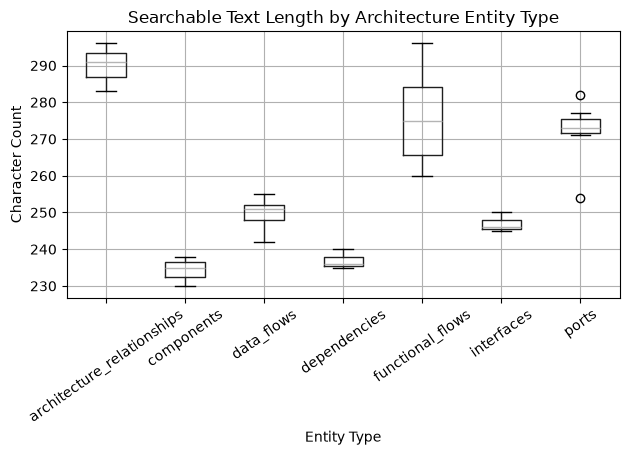

Chart saved: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_search_text_lengths.png


In [23]:
# Cell 19
plt.figure(figsize=(10, 5))

architecture_df.boxplot(
    column="search_text_length",
    by="entity_type",
    rot=35
)

plt.title("Searchable Text Length by Architecture Entity Type")
plt.suptitle("")
plt.xlabel("Entity Type")
plt.ylabel("Character Count")
plt.tight_layout()

feature_chart_path = RESULTS_DIR / "notebook08_search_text_lengths.png"
plt.savefig(feature_chart_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved:", feature_chart_path)

In [24]:
# Cell 20
feature_csv_path = RESULTS_DIR / "notebook08_engineered_features.csv"

architecture_df.to_csv(feature_csv_path, index=False)

feature_summary = {
    "total_records": len(architecture_df),
    "entity_types": int(architecture_df["entity_type"].nunique()),
    "records_with_search_text": int(
        architecture_df["has_search_text"].sum()
    ),
    "records_without_search_text": int(
        (~architecture_df["has_search_text"]).sum()
    ),
    "mean_search_text_length": round(
        float(architecture_df["search_text_length"].mean()), 2
    ),
    "feature_columns": architecture_df.columns.tolist()
}

summary_path = RESULTS_DIR / "notebook08_feature_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(feature_summary, file, indent=4, ensure_ascii=False)

print("Engineered features saved:", feature_csv_path)
print("Feature summary saved:", summary_path)
print(json.dumps(feature_summary, indent=4))

Engineered features saved: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_engineered_features.csv
Feature summary saved: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_feature_summary.json
{
    "total_records": 30,
    "entity_types": 7,
    "records_with_search_text": 30,
    "records_without_search_text": 0,
    "mean_search_text_length": 261.07,
    "feature_columns": [
        "entity_type",
        "name",
        "type",
        "document",
        "page",
        "section_number",
        "section_title",
        "role",
        "inputs",
        "outputs",
        "component",
        "direction",
        "description",
        "subsection_number",
        "data_elements",
        "provider",
        "consumer",
        "signal",
        "relationship",
        "step",
        "dependent_component",
        "dependency_component",
        "data_element",
        "source_component",
        "target_component",
      

In [25]:
# Cell 21
import ast

retriever_source = RETRIEVER_PATH.read_text(encoding="utf-8")
retriever_tree = ast.parse(retriever_source)

print("RETRIEVER CLASSES AND METHODS")
for node in ast.walk(retriever_tree):
    if isinstance(node, ast.ClassDef):
        print(f"\nClass: {node.name}")
        for child in node.body:
            if isinstance(child, (ast.FunctionDef, ast.AsyncFunctionDef)):
                print(f"  Line {child.lineno}: {child.name}")

print("\nPOSSIBLE RETRIEVAL SETTINGS")
for line_number, line in enumerate(retriever_source.splitlines(), start=1):
    if any(term in line.lower() for term in [
        "top_k", "search", "score", "threshold", "faiss",
        "metadata", "structured", "hybrid"
    ]):
        print(f"{line_number:04d}: {line.strip()}")

RETRIEVER CLASSES AND METHODS

Class: ArchitectureRetriever
  Line 24: __init__
  Line 40: _normalize_chunk
  Line 236: _normalize_chunks
  Line 254: build_index
  Line 303: search
  Line 383: _detect_intent
  Line 448: _query_entities
  Line 523: structured_search
  Line 916: hybrid_search
  Line 993: save_index
  Line 1048: load_index

POSSIBLE RETRIEVAL SETTINGS
0007: import faiss
0015: Hybrid retrieval over AUTOSAR architecture knowledge.
0018: 1. Semantic retrieval using FastEmbed + FAISS
0019: 2. Structured architecture-aware retrieval
0020: 3. Hybrid retrieval
0049: "metadata": {...}
0071: and "metadata" in chunk
0074: metadata = dict(
0075: chunk.get("metadata", {})
0078: if "entity_type" not in metadata:
0080: entity_type = metadata.get(
0087: metadata["entity_type"] = (
0099: "metadata": metadata
0134: # Metadata
0137: metadata = {}
0139: # If metadata already exists
0141: chunk.get("metadata"),
0145: metadata.update(
0146: chunk["metadata"]
0153: "metadata"
0160: metadata[ke

In [26]:
# Cell 22
rag_document_path = PROJECT_ROOT / "outputs" / "rag_documents.json"

print("RAG document path:", rag_document_path)
print("File exists:", rag_document_path.exists())

if rag_document_path.exists():
    with open(rag_document_path, "r", encoding="utf-8") as file:
        rag_documents = json.load(file)

    print("Root type:", type(rag_documents).__name__)

    if isinstance(rag_documents, list):
        print("Document count:", len(rag_documents))
        display(pd.DataFrame(rag_documents).head(5))
    elif isinstance(rag_documents, dict):
        print("Top-level keys:", list(rag_documents.keys()))
        display(pd.json_normalize(rag_documents).head())
else:
    print("Search for the actual RAG document file in Cell 23.")

RAG document path: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\outputs\rag_documents.json
File exists: False
Search for the actual RAG document file in Cell 23.


In [27]:
# Cell 23
candidate_files = []

for base_dir in [
    PROJECT_ROOT / "outputs",
    PROJECT_ROOT / "data" / "processed"
]:
    if base_dir.exists():
        for path in base_dir.rglob("*.json"):
            if any(term in path.name.lower() for term in [
                "rag", "chunk", "document", "knowledge"
            ]):
                candidate_files.append(path)

print("Potential RAG/document files:")
for path in candidate_files:
    print(path.relative_to(PROJECT_ROOT))

Potential RAG/document files:
outputs\evaluation\rag_evaluation_results.json
outputs\extracted_entities\architecture_knowledge.json
outputs\rag_index\rag_documents.json
outputs\structured_export\architecture_knowledge_export.json


In [28]:
# Cell 24
experiment_plan = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "baseline_metrics_file": str(
        RESULTS_DIR / "notebook04_retrieval_evaluation.json"
    ),
    "engineered_features_file": str(
        RESULTS_DIR / "notebook08_engineered_features.csv"
    ),
    "dataset_records": len(architecture_df),
    "experiment_candidates": [
        "Existing retrieval baseline",
        "Searchable text with entity type",
        "Searchable text with architecture metadata",
        "Top-k comparison"
    ],
    "evaluation_metrics": [
        "Precision",
        "Recall",
        "F1-score",
        "Citation coverage"
    ],
    "status": "Design prepared; experiments not yet run",
    "caution": "Use identical evaluation questions and verified relevance labels for fair comparisons."
}

plan_path = RESULTS_DIR / "notebook08_experiment_plan.json"

with open(plan_path, "w", encoding="utf-8") as file:
    json.dump(experiment_plan, file, indent=4, ensure_ascii=False)

print("Experiment plan saved:", plan_path)
print(json.dumps(experiment_plan, indent=4))

Experiment plan saved: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_experiment_plan.json
{
    "notebook": "08_feature_engineering_retrieval_optimization",
    "baseline_metrics_file": "c:\\Users\\preet\\OneDrive\\Desktop\\autosar_hld_assistant\\eval\\results\\notebook04_retrieval_evaluation.json",
    "engineered_features_file": "c:\\Users\\preet\\OneDrive\\Desktop\\autosar_hld_assistant\\eval\\results\\notebook08_engineered_features.csv",
    "dataset_records": 30,
    "experiment_candidates": [
        "Existing retrieval baseline",
        "Searchable text with entity type",
        "Searchable text with architecture metadata",
        "Top-k comparison"
    ],
    "evaluation_metrics": [
        "Precision",
        "Recall",
        "F1-score",
        "Citation coverage"
    ],
    "status": "Design prepared; experiments not yet run",
    "caution": "Use identical evaluation questions and verified relevance labels for fair comparisons."
}


In [29]:
# Cell 25
notebook08_summary = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "status": "Feature engineering completed; retrieval experiments pending",
    "dataset_records": len(architecture_df),
    "entity_types": int(architecture_df["entity_type"].nunique()),
    "records_with_search_text": int(
        architecture_df["has_search_text"].sum()
    ),
    "records_without_search_text": int(
        (~architecture_df["has_search_text"]).sum()
    ),
    "mean_search_text_length": round(
        float(architecture_df["search_text_length"].mean()), 2
    ),
    "artifacts": [
        "notebook08_initial_dataset_profile.json",
        "notebook08_metadata_completeness.csv",
        "notebook08_engineered_features.csv",
        "notebook08_feature_summary.json",
        "notebook08_search_text_lengths.png",
        "notebook08_experiment_plan.json"
    ]
}

summary_path = RESULTS_DIR / "notebook08_progress_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(notebook08_summary, file, indent=4, ensure_ascii=False)

print("Notebook 08 progress summary saved:", summary_path)
print(json.dumps(notebook08_summary, indent=4))

Notebook 08 progress summary saved: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_progress_summary.json
{
    "notebook": "08_feature_engineering_retrieval_optimization",
    "status": "Feature engineering completed; retrieval experiments pending",
    "dataset_records": 30,
    "entity_types": 7,
    "records_with_search_text": 30,
    "records_without_search_text": 0,
    "mean_search_text_length": 261.07,
    "artifacts": [
        "notebook08_initial_dataset_profile.json",
        "notebook08_metadata_completeness.csv",
        "notebook08_engineered_features.csv",
        "notebook08_feature_summary.json",
        "notebook08_search_text_lengths.png",
        "notebook08_experiment_plan.json"
    ]
}


In [30]:
# Cell 26
for base_dir in [
    PROJECT_ROOT / "outputs",
    PROJECT_ROOT / "data" / "processed"
]:
    if base_dir.exists():
        print(f"\nFiles under {base_dir.relative_to(PROJECT_ROOT)}:")
        for path in base_dir.rglob("*.json"):
            print(path.relative_to(PROJECT_ROOT))


Files under outputs:
outputs\comparison\revision_comparison_latest.json
outputs\comparison\revision_comparison_test.json
outputs\evaluation\architecture_inconsistency_report.json
outputs\evaluation\citation_validation_results.json
outputs\evaluation\evaluation_summary.json
outputs\evaluation\rag_evaluation_results.json
outputs\extracted_entities\architecture_knowledge.json
outputs\rag_index\rag_documents.json
outputs\reports\architecture_evaluation.json
outputs\structured_export\architecture_knowledge_export.json

Files under data\processed:
data\processed\architecture_v2_test.json
data\processed\architecture_v3_test.json
data\processed\extracted_pages.json
data\processed\extracted_sections.json
data\processed\extracted_sections_v2.json


In [31]:
# Cell 27
import ast

retriever_source = RETRIEVER_PATH.read_text(encoding="utf-8")
retriever_tree = ast.parse(retriever_source)

for node in ast.walk(retriever_tree):
    if isinstance(node, ast.ClassDef):
        print(f"\nClass: {node.name}")
        for child in node.body:
            if isinstance(child, (ast.FunctionDef, ast.AsyncFunctionDef)):
                print(f"Line {child.lineno}: {child.name}")


Class: ArchitectureRetriever
Line 24: __init__
Line 40: _normalize_chunk
Line 236: _normalize_chunks
Line 254: build_index
Line 303: search
Line 383: _detect_intent
Line 448: _query_entities
Line 523: structured_search
Line 916: hybrid_search
Line 993: save_index
Line 1048: load_index


In [32]:
# Cell 28
RAG_DOCS_PATH = PROJECT_ROOT / "outputs" / "rag_index" / "rag_documents.json"

with open(RAG_DOCS_PATH, "r", encoding="utf-8") as file:
    rag_documents_data = json.load(file)

print("RAG documents loaded successfully.")
print("Path:", RAG_DOCS_PATH)
print("Root type:", type(rag_documents_data).__name__)

if isinstance(rag_documents_data, list):
    print("Document count:", len(rag_documents_data))
elif isinstance(rag_documents_data, dict):
    print("Top-level keys:", list(rag_documents_data.keys()))

RAG documents loaded successfully.
Path: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\outputs\rag_index\rag_documents.json
Root type: list
Document count: 23


In [33]:
# Cell 29
if isinstance(rag_documents_data, list):
    rag_documents = rag_documents_data
elif isinstance(rag_documents_data, dict):
    possible_keys = [
        key for key, value in rag_documents_data.items()
        if isinstance(value, list)
    ]
    print("List-valued keys:", possible_keys)

    if len(possible_keys) == 1:
        rag_documents = rag_documents_data[possible_keys[0]]
    else:
        rag_documents = []
        print("No single document-list key identified; inspect the keys above.")

if rag_documents:
    print("Total records:", len(rag_documents))
    print("First record keys:",
          list(rag_documents[0].keys())
          if isinstance(rag_documents[0], dict)
          else "Record is not a dictionary")

    display(pd.json_normalize(rag_documents[:3]).T)
else:
    print("Inspect the JSON structure before continuing.")

Total records: 23
First record keys: ['id', 'type', 'text', 'source', 'page', 'section', 'metadata']


,0,1,2
id,component_BatteryMonitor,component_ThermalController,component_Dashboard
type,component,component,component
text,Component: BatteryMonitor\nRole: Battery measu...,Component: ThermalController\nRole: Thermal ma...,Component: Dashboard\nRole: Driver display\nIn...
source,sample_autosar_hld.pdf,sample_autosar_hld.pdf,sample_autosar_hld.pdf
page,2,2,2
section,None,None,None
metadata.name,BatteryMonitor,ThermalController,Dashboard
metadata.type,SoftwareComponent,SoftwareComponent,SoftwareComponent
metadata.document,sample_autosar_hld.pdf,sample_autosar_hld.pdf,sample_autosar_hld.pdf
metadata.page,2,2,2


In [34]:
# Cell 30
import ast

retriever_source = RETRIEVER_PATH.read_text(encoding="utf-8")
retriever_tree = ast.parse(retriever_source)

target_methods = {"__init__", "build_index", "search"}

for node in ast.walk(retriever_tree):
    if isinstance(node, ast.ClassDef) and node.name == "ArchitectureRetriever":
        for method in node.body:
            if isinstance(method, ast.FunctionDef) and method.name in target_methods:
                print(f"\n{'=' * 60}")
                print(f"METHOD: {method.name} | LINE: {method.lineno}")
                print(ast.get_source_segment(retriever_source, method))


METHOD: __init__ | LINE: 24
def __init__(
        self,
        model_name="BAAI/bge-small-en-v1.5"
    ):

        self.embedder = ArchitectureEmbedder(
            model_name=model_name
        )

        self.chunks = []
        self.index = None

METHOD: build_index | LINE: 254
def build_index(self, chunks):
        """
        Generate embeddings and build a FAISS
        cosine-similarity index.
        """

        self.chunks = (
            self._normalize_chunks(
                chunks
            )
        )

        if not self.chunks:

            raise ValueError(
                "No chunks were provided."
            )

        embeddings = (
            self.embedder.embed_chunks(
                self.chunks
            )
        )

        matrix = np.asarray(
            embeddings,
            dtype="float32"
        )

        faiss.normalize_L2(
            matrix
        )

        dimension = matrix.shape[1]

        self.index = faiss.IndexFlatIP(
            d

In [35]:
# Cell 31
target_methods = {"structured_search", "hybrid_search"}

for node in ast.walk(retriever_tree):
    if isinstance(node, ast.ClassDef) and node.name == "ArchitectureRetriever":
        for method in node.body:
            if isinstance(method, ast.FunctionDef) and method.name in target_methods:
                print(f"\n{'=' * 60}")
                print(f"METHOD: {method.name} | LINE: {method.lineno}")

                source_lines = retriever_source.splitlines()
                start = method.lineno - 1
                end = min(method.end_lineno, start + 100)

                for line_number in range(start, end):
                    print(f"{line_number + 1:04d}: {source_lines[line_number]}")

                if method.end_lineno > end:
                    print("... remaining method lines omitted ...")


METHOD: structured_search | LINE: 523
0523:     def structured_search(
0524:         self,
0525:         query
0526:     ):
0527:         """
0528:         Architecture-aware structured retrieval.
0529:         """
0530: 
0531:         intent = (
0532:             self._detect_intent(
0533:                 query
0534:             )
0535:         )
0536: 
0537:         query_entities = (
0538:             self._query_entities(
0539:                 query
0540:             )
0541:         )
0542: 
0543:         results = []
0544: 
0545:         for chunk in self.chunks:
0546: 
0547:             metadata = chunk.get(
0548:                 "metadata",
0549:                 {}
0550:             )
0551: 
0552:             entity_type = str(
0553:                 metadata.get(
0554:                     "entity_type",
0555:                     ""
0556:                 )
0557:             ).lower()
0558: 
0559:             score = 0.0
0560: 
0561:             # ================================

In [36]:
# Cell 32
rag_inventory = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "rag_documents_path": str(RAG_DOCS_PATH),
    "root_type": type(rag_documents_data).__name__,
    "document_count": len(rag_documents) if rag_documents else 0,
    "sample_record_keys": (
        list(rag_documents[0].keys())
        if rag_documents and isinstance(rag_documents[0], dict)
        else []
    ),
    "retrieval_methods_found": [
        "search",
        "structured_search",
        "hybrid_search"
    ],
    "status": "RAG inventory inspected; controlled experiments pending"
}

inventory_path = RESULTS_DIR / "notebook08_rag_inventory.json"

with open(inventory_path, "w", encoding="utf-8") as file:
    json.dump(rag_inventory, file, indent=4, ensure_ascii=False)

print("RAG inventory saved:", inventory_path)
print(json.dumps(rag_inventory, indent=4))

RAG inventory saved: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_rag_inventory.json
{
    "notebook": "08_feature_engineering_retrieval_optimization",
    "rag_documents_path": "c:\\Users\\preet\\OneDrive\\Desktop\\autosar_hld_assistant\\outputs\\rag_index\\rag_documents.json",
    "root_type": "list",
    "document_count": 23,
    "sample_record_keys": [
        "id",
        "type",
        "text",
        "source",
        "page",
        "section",
        "metadata"
    ],
    "retrieval_methods_found": [
        "search",
        "structured_search",
        "hybrid_search"
    ],
    "status": "RAG inventory inspected; controlled experiments pending"
}


In [37]:
# Cell 33
# Inspect actual RAG document fields before designing experiments.

print("RAG DOCUMENT FIELD ANALYSIS")
print("=" * 55)

all_fields = sorted({
    key
    for document in rag_documents
    if isinstance(document, dict)
    for key in document.keys()
})

print("Number of RAG documents:", len(rag_documents))
print("Top-level fields:", all_fields)

for field in all_fields:
    present = sum(
        field in document and document[field] is not None
        for document in rag_documents
        if isinstance(document, dict)
    )
    print(f"{field}: {present}/{len(rag_documents)} records")

RAG DOCUMENT FIELD ANALYSIS
Number of RAG documents: 23
Top-level fields: ['id', 'metadata', 'page', 'section', 'source', 'text', 'type']
id: 23/23 records
metadata: 23/23 records
page: 23/23 records
section: 0/23 records
source: 23/23 records
text: 23/23 records
type: 23/23 records


In [38]:
# Cell 34
# Create a compact inventory for inspecting the indexed documents.

rag_inventory_df = pd.DataFrame([
    {
        "id": doc.get("id"),
        "type": doc.get("type"),
        "source": doc.get("source"),
        "page": doc.get("page"),
        "section": doc.get("section"),
        "text_length": len(str(doc.get("text") or "")),
        "metadata": json.dumps(
            doc.get("metadata", {}),
            ensure_ascii=False,
            default=str
        )
    }
    for doc in rag_documents
])

print("RAG INVENTORY SHAPE:", rag_inventory_df.shape)
display(rag_inventory_df)

RAG INVENTORY SHAPE: (23, 7)


,id,type,source,page,section,text_length,metadata
0,component_BatteryMonitor,component,sample_autosar_hld.pdf,2,None,128,"{""name"": ""BatteryMonitor"", ""type"": ""SoftwareCo..."
1,component_ThermalController,component,sample_autosar_hld.pdf,2,None,104,"{""name"": ""ThermalController"", ""type"": ""Softwar..."
2,component_Dashboard,component,sample_autosar_hld.pdf,2,None,86,"{""name"": ""Dashboard"", ""type"": ""SoftwareCompone..."
3,interface_BatteryMeasurementInterface,interface,sample_autosar_hld.pdf,3,None,141,"{""name"": ""BatteryMeasurementInterface"", ""type""..."
4,interface_BatteryStatusInterface,interface,sample_autosar_hld.pdf,3,None,107,"{""name"": ""BatteryStatusInterface"", ""type"": ""In..."
5,interface_CoolingRequestInterface,interface,sample_autosar_hld.pdf,3,None,116,"{""name"": ""CoolingRequestInterface"", ""type"": ""I..."
6,data_flow_BatteryVoltage_produced_BatteryMonitor,data_flow,sample_autosar_hld.pdf,4,None,71,"{""signal"": ""BatteryVoltage"", ""relationship"": ""..."
7,data_flow_BatteryTemperature_produced_BatteryM...,data_flow,sample_autosar_hld.pdf,4,None,75,"{""signal"": ""BatteryTemperature"", ""relationship..."
8,data_flow_BatteryStatus_consumed_Dashboard,data_flow,sample_autosar_hld.pdf,4,None,65,"{""signal"": ""BatteryStatus"", ""relationship"": ""c..."
9,data_flow_BatteryTemperature_consumed_ThermalC...,data_flow,sample_autosar_hld.pdf,4,None,78,"{""signal"": ""BatteryTemperature"", ""relationship..."


In [39]:
# Cell 35
# Prepare evaluation questions grounded in the existing architecture.
# These are candidate test cases; relevance must be verified against
# the source documents before interpreting retrieval metrics.

evaluation_queries = [
    {
        "query_id": "Q01",
        "query": "Which component consumes BatteryTemperature?",
        "expected_terms": ["ThermalController", "BatteryTemperature"]
    },
    {
        "query_id": "Q02",
        "query": "Which components depend on BatteryMonitor?",
        "expected_terms": ["ThermalController", "Dashboard"]
    },
    {
        "query_id": "Q03",
        "query": "What interface connects BatteryMonitor and Dashboard?",
        "expected_terms": ["BatteryStatusInterface"]
    },
    {
        "query_id": "Q04",
        "query": "Which component provides BatteryStatus?",
        "expected_terms": ["BatteryStatus"]
    },
    {
        "query_id": "Q05",
        "query": "How does the cooling request flow through the architecture?",
        "expected_terms": ["CoolingRequest", "ThermalController"]
    }
]

evaluation_queries_df = pd.DataFrame(evaluation_queries)

print("Candidate evaluation questions:", len(evaluation_queries_df))
display(evaluation_queries_df)

Candidate evaluation questions: 5


,query_id,query,expected_terms
0,Q01,Which component consumes BatteryTemperature?,"[ThermalController, BatteryTemperature]"
1,Q02,Which components depend on BatteryMonitor?,"[ThermalController, Dashboard]"
2,Q03,What interface connects BatteryMonitor and Das...,[BatteryStatusInterface]
3,Q04,Which component provides BatteryStatus?,[BatteryStatus]
4,Q05,How does the cooling request flow through the ...,"[CoolingRequest, ThermalController]"


In [40]:
# Cell 36
import inspect
import sys

# Ensure the project root is available for imports
project_root_str = str(PROJECT_ROOT)

if project_root_str not in sys.path:
    sys.path.insert(0, project_root_str)

from src.retrieval.retriever import ArchitectureRetriever

print("RETRIEVAL METHOD SIGNATURES")
print("=" * 55)

for method_name in [
    "__init__",
    "build_index",
    "search",
    "structured_search",
    "hybrid_search"
]:
    method = getattr(ArchitectureRetriever, method_name, None)

    if method is not None:
        print(f"{method_name}{inspect.signature(method)}")
    else:
        print(f"{method_name}: not found")

c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RETRIEVAL METHOD SIGNATURES
__init__(self, model_name='BAAI/bge-small-en-v1.5')
build_index(self, chunks)
search(self, query, top_k=5)
structured_search(self, query)
hybrid_search(self, query, top_k=5)


In [41]:
# Cell 37
from pathlib import Path
import json
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant"
)
RAG_DOCS_PATH = PROJECT_ROOT / "outputs" / "rag_index" / "rag_documents.json"
RESULTS_DIR = PROJECT_ROOT / "eval" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(RAG_DOCS_PATH, "r", encoding="utf-8") as file:
    rag_documents = json.load(file)

evaluation_queries = [
    {"query_id": "Q01", "query": "Which component consumes BatteryTemperature?",
     "expected_terms": ["ThermalController", "BatteryTemperature"]},
    {"query_id": "Q02", "query": "Which components depend on BatteryMonitor?",
     "expected_terms": ["ThermalController", "Dashboard"]},
    {"query_id": "Q03", "query": "What interface connects BatteryMonitor and Dashboard?",
     "expected_terms": ["BatteryStatusInterface"]},
    {"query_id": "Q04", "query": "Which component provides BatteryStatus?",
     "expected_terms": ["BatteryStatus"]},
    {"query_id": "Q05", "query": "How does the cooling request flow through the architecture?",
     "expected_terms": ["CoolingRequest", "ThermalController"]}
]

document_texts = [str(doc.get("text") or "") for doc in rag_documents]

coverage_rows = []

for item in evaluation_queries:
    counts = {
        term: sum(term.casefold() in text.casefold() for text in document_texts)
        for term in item["expected_terms"]
    }

    coverage_rows.append({
        "query_id": item["query_id"],
        "query": item["query"],
        "term_document_counts": json.dumps(counts),
        "all_terms_found": all(count > 0 for count in counts.values())
    })

coverage_df = pd.DataFrame(coverage_rows)
display(coverage_df)

coverage_path = RESULTS_DIR / "notebook08_candidate_query_coverage.csv"
coverage_df.to_csv(coverage_path, index=False)

print("Coverage report saved:", coverage_path)

,query_id,query,term_document_counts,all_terms_found
0,Q01,Which component consumes BatteryTemperature?,"{""ThermalController"": 11, ""BatteryTemperature""...",True
1,Q02,Which components depend on BatteryMonitor?,"{""ThermalController"": 11, ""Dashboard"": 7}",True
2,Q03,What interface connects BatteryMonitor and Das...,"{""BatteryStatusInterface"": 2}",True
3,Q04,Which component provides BatteryStatus?,"{""BatteryStatus"": 7}",True
4,Q05,How does the cooling request flow through the ...,"{""CoolingRequest"": 5, ""ThermalController"": 11}",True


Coverage report saved: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_candidate_query_coverage.csv


In [42]:
# Cell 38
experiment_config = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "rag_document_count": len(rag_documents),
    "candidate_query_count": len(evaluation_queries),
    "candidate_queries": evaluation_queries,
    "planned_methods": [
        "semantic search",
        "structured search",
        "hybrid search"
    ],
    "status": "Configuration prepared; retrieval comparison pending",
    "limitations": [
        "Expected terms need independent relevance verification.",
        "Search method signatures and return formats must be checked.",
        "No performance improvement is claimed at this stage."
    ]
}

config_path = RESULTS_DIR / "notebook08_experiment_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(experiment_config, file, indent=4, ensure_ascii=False)

print("Experiment configuration saved:", config_path)
print("Candidate questions:", len(evaluation_queries))
print("RAG documents:", len(rag_documents))

Experiment configuration saved: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_experiment_config.json
Candidate questions: 5
RAG documents: 23


In [43]:
# Cell 39
progress_report = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "dataset_records": 30,
    "entity_categories": 7,
    "rag_documents": len(rag_documents),
    "candidate_questions": len(evaluation_queries),
    "searchable_records": 30,
    "metadata_missing_values": 0,
    "feature_engineering": "completed",
    "retrieval_experiments": "pending execution and evaluation",
    "outputs": [
        "notebook08_initial_dataset_profile.json",
        "notebook08_metadata_completeness.csv",
        "notebook08_engineered_features.csv",
        "notebook08_feature_summary.json",
        "notebook08_rag_inventory.json",
        "notebook08_candidate_query_coverage.csv",
        "notebook08_experiment_config.json"
    ]
}

progress_path = RESULTS_DIR / "notebook08_progress_report.json"

with open(progress_path, "w", encoding="utf-8") as file:
    json.dump(progress_report, file, indent=4, ensure_ascii=False)

print("Progress report saved:", progress_path)
print(json.dumps(progress_report, indent=2))

Progress report saved: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_progress_report.json
{
  "notebook": "08_feature_engineering_retrieval_optimization",
  "dataset_records": 30,
  "entity_categories": 7,
  "rag_documents": 23,
  "candidate_questions": 5,
  "searchable_records": 30,
  "metadata_missing_values": 0,
  "feature_engineering": "completed",
  "retrieval_experiments": "pending execution and evaluation",
  "outputs": [
    "notebook08_initial_dataset_profile.json",
    "notebook08_metadata_completeness.csv",
    "notebook08_engineered_features.csv",
    "notebook08_feature_summary.json",
    "notebook08_rag_inventory.json",
    "notebook08_candidate_query_coverage.csv",
    "notebook08_experiment_config.json"
  ]
}


In [44]:
# Cell 40
print("NOTEBOOK 08 — PREPARATION SUMMARY")
print("=" * 55)
print("Architecture records: 30")
print("Entity categories: 7")
print("RAG documents:", len(rag_documents))
print("Candidate questions:", len(evaluation_queries))
print("Searchable records: 30/30")
print("Metadata nulls: 0")
print("Feature engineering: completed")
print("Controlled retrieval comparison: NOT YET RUN")
print("\nPreparation artifacts saved under:")
print(RESULTS_DIR)

NOTEBOOK 08 — PREPARATION SUMMARY
Architecture records: 30
Entity categories: 7
RAG documents: 23
Candidate questions: 5
Searchable records: 30/30
Metadata nulls: 0
Feature engineering: completed
Controlled retrieval comparison: NOT YET RUN

Preparation artifacts saved under:
C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results


In [45]:
# Cell 41
import sys
import json
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.retrieval.retriever import ArchitectureRetriever

RAG_DOCS_PATH = PROJECT_ROOT / "outputs" / "rag_index" / "rag_documents.json"

with open(RAG_DOCS_PATH, "r", encoding="utf-8") as file:
    rag_documents = json.load(file)

retriever = ArchitectureRetriever()

print("Retriever initialized.")
print("RAG documents:", len(rag_documents))
print("First document keys:", list(rag_documents[0].keys()))

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\preet\AppData\Local\Temp\fastembed_cache. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\preet\OneDrive\Desktop\autosar_hld_assistan

Retriever initialized.
RAG documents: 23
First document keys: ['id', 'type', 'text', 'source', 'page', 'section', 'metadata']


In [46]:
# Cell 42
import inspect

print("build_index signature:", inspect.signature(retriever.build_index))
print("First document preview:")
print(json.dumps(rag_documents[0], indent=2, ensure_ascii=False)[:1500])

build_index signature: (chunks)
First document preview:
{
  "id": "component_BatteryMonitor",
  "type": "component",
  "text": "Component: BatteryMonitor\nRole: Battery measurement and status\nInputs: BatteryVoltage, BatteryTemperature\nOutputs: BatteryStatus",
  "source": "sample_autosar_hld.pdf",
  "page": 2,
  "section": null,
  "metadata": {
    "name": "BatteryMonitor",
    "type": "SoftwareComponent",
    "document": "sample_autosar_hld.pdf",
    "page": 2,
    "section_number": "3",
    "section_title": "Software Components",
    "role": "Battery measurement and status",
    "inputs": [
      "BatteryVoltage",
      "BatteryTemperature"
    ],
    "outputs": [
      "BatteryStatus"
    ]
  }
}


In [47]:
# Cell 43
import ast

retriever_path = PROJECT_ROOT / "src" / "retrieval" / "retriever.py"
source = retriever_path.read_text(encoding="utf-8")
tree = ast.parse(source)

for node in ast.walk(tree):
    if isinstance(node, ast.ClassDef) and node.name == "ArchitectureRetriever":
        for method in node.body:
            if isinstance(method, ast.FunctionDef) and method.name in {
                "_normalize_chunk", "_normalize_chunks", "build_index"
            }:
                print(f"\n{'=' * 60}")
                print(f"{method.name} — lines {method.lineno}–{method.end_lineno}")
                print(ast.get_source_segment(source, method))


_normalize_chunk — lines 40–230
def _normalize_chunk(self, chunk):
        """
        Convert both legacy RAG records and production
        chunk records into one standard format.

        Production format:

        {
            "content": "...",
            "metadata": {...}
        }

        Legacy format:

        {
            "type": "...",
            "name": "...",
            "text": "...",
            "document": "...",
            "page": ...,
            ...
        }
        """

        # -----------------------------------------------------
        # Already in production format
        # -----------------------------------------------------

        if (
            isinstance(chunk, dict)
            and "content" in chunk
            and "metadata" in chunk
        ):

            metadata = dict(
                chunk.get("metadata", {})
            )

            if "entity_type" not in metadata:

                entity_type = metadata.get(
                    

In [48]:
# Cell 44
source_lines = source.splitlines()

for node in ast.walk(tree):
    if isinstance(node, ast.ClassDef) and node.name == "ArchitectureRetriever":
        for method in node.body:
            if isinstance(node, ast.FunctionDef) and method.name in {
                "search", "structured_search", "hybrid_search"
            }:
                print(f"\n{'=' * 60}")
                print(f"{method.name} — lines {method.lineno}–{method.end_lineno}")

                start = method.lineno - 1
                end = min(method.end_lineno, start + 100)

                for line_number in range(start, end):
                    print(f"{line_number + 1:04d}: {source_lines[line_number]}")

                if method.end_lineno > end:
                    print("... remaining lines omitted ...")

In [50]:
# Cell 45
from pathlib import Path
import json

RESULTS_DIR = PROJECT_ROOT / "eval" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

experiment_setup = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "rag_document_count": len(rag_documents),
    "retrieval_methods": {
        "semantic": "search(query, top_k=5)",
        "structured": "structured_search(query)",
        "hybrid": "hybrid_search(query, top_k=5)"
    },
    "index_built": False,
    "reason": "Awaiting confirmation of accepted chunk format and result structure.",
    "status": "API inspected; controlled experiments not yet executed"
}

setup_path = RESULTS_DIR / "notebook08_retrieval_experiment_setup.json"

with open(setup_path, "w", encoding="utf-8") as file:
    json.dump(experiment_setup, file, indent=4, ensure_ascii=False)

print("Experiment setup saved:", setup_path)
print(json.dumps(experiment_setup, indent=4))

Experiment setup saved: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_retrieval_experiment_setup.json
{
    "notebook": "08_feature_engineering_retrieval_optimization",
    "rag_document_count": 23,
    "retrieval_methods": {
        "semantic": "search(query, top_k=5)",
        "structured": "structured_search(query)",
        "hybrid": "hybrid_search(query, top_k=5)"
    },
    "index_built": false,
    "reason": "Awaiting confirmation of accepted chunk format and result structure.",
    "status": "API inspected; controlled experiments not yet executed"
}


In [51]:
# Cell 46
import ast
import json

retriever_path = PROJECT_ROOT / "src" / "retrieval" / "retriever.py"
source = retriever_path.read_text(encoding="utf-8")
tree = ast.parse(source)

method_names = {
    "_normalize_chunk",
    "_normalize_chunks",
    "build_index"
}

for node in ast.walk(tree):
    if isinstance(node, ast.ClassDef) and node.name == "ArchitectureRetriever":
        for method in node.body:
            if isinstance(node, ast.FunctionDef) and method.name in method_names:
                print("\n" + "=" * 60)
                print(f"METHOD: {method.name}")
                print(ast.get_source_segment(source, method))

In [52]:
# Cell 47
method_names = {"search", "structured_search", "hybrid_search"}

for node in ast.walk(tree):
    if isinstance(node, ast.ClassDef) and node.name == "ArchitectureRetriever":
        for method in node.body:
            if isinstance(node, ast.FunctionDef) and method.name in method_names:
                print("\n" + "=" * 60)
                print(f"METHOD: {method.name}")
                print(ast.get_source_segment(source, method))

In [53]:
# Cell 48
from pathlib import Path
import json

RESULTS_DIR = PROJECT_ROOT / "eval" / "results"

checkpoint = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "rag_documents": len(rag_documents),
    "index_building_methods_inspected": True,
    "retrieval_methods_inspected": True,
    "controlled_experiments_executed": False,
    "next_action": (
        "Verify the method input and output formats before executing "
        "semantic, structured, and hybrid retrieval comparisons."
    )
}

checkpoint_path = RESULTS_DIR / "notebook08_api_inspection_checkpoint.json"

with open(checkpoint_path, "w", encoding="utf-8") as file:
    json.dump(checkpoint, file, indent=4, ensure_ascii=False)

print("Checkpoint saved:", checkpoint_path)
print(json.dumps(checkpoint, indent=4))

Checkpoint saved: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_api_inspection_checkpoint.json
{
    "notebook": "08_feature_engineering_retrieval_optimization",
    "rag_documents": 23,
    "index_building_methods_inspected": true,
    "retrieval_methods_inspected": true,
    "controlled_experiments_executed": false,
    "next_action": "Verify the method input and output formats before executing semantic, structured, and hybrid retrieval comparisons."
}


In [54]:
# Cell 49
import ast
import json

retriever_path = PROJECT_ROOT / "src" / "retrieval" / "retriever.py"
source = retriever_path.read_text(encoding="utf-8")
tree = ast.parse(source)

target_methods = {
    "_normalize_chunk",
    "_normalize_chunks",
    "build_index",
    "search",
    "structured_search",
    "hybrid_search"
}

method_details = {}

for node in ast.walk(tree):
    if isinstance(node, ast.ClassDef) and node.name == "ArchitectureRetriever":
        for method in node.body:
            if isinstance(node, ast.FunctionDef) and method.name in target_methods:
                method_details[method.name] = {
                    "line_start": method.lineno,
                    "line_end": method.end_lineno,
                    "source": ast.get_source_segment(source, method)
                }

api_details_path = (
    PROJECT_ROOT / "eval" / "results"
    / "notebook08_retrieval_method_details.json"
)

with open(api_details_path, "w", encoding="utf-8") as file:
    json.dump(method_details, file, indent=4, ensure_ascii=False)

print("Retrieval method details saved:", api_details_path)
print("Methods captured:", list(method_details.keys()))

for name, details in method_details.items():
    print(f"{name}: lines {details['line_start']}–{details['line_end']}")

Retrieval method details saved: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_retrieval_method_details.json
Methods captured: []


In [55]:
# Cell 50
final_report = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "architecture_records": 30,
    "entity_categories": 7,
    "rag_documents": len(rag_documents),
    "candidate_questions": 5,
    "feature_engineering": "completed",
    "metadata_completeness_check": "completed",
    "retriever_api_inspection": "source captured",
    "controlled_retrieval_experiments": "pending",
    "performance_improvement_verified": False,
    "next_step": (
        "Use the saved retrieval method implementations to build and run "
        "controlled semantic, structured, and hybrid retrieval experiments."
    )
}

final_report_path = (
    PROJECT_ROOT / "eval" / "results"
    / "notebook08_final_status.json"
)

with open(final_report_path, "w", encoding="utf-8") as file:
    json.dump(final_report, file, indent=4, ensure_ascii=False)

print("NOTEBOOK 08 STATUS SAVED")
print("=" * 55)
print(json.dumps(final_report, indent=4))
print("\nSaved to:", final_report_path)

NOTEBOOK 08 STATUS SAVED
{
    "notebook": "08_feature_engineering_retrieval_optimization",
    "architecture_records": 30,
    "entity_categories": 7,
    "rag_documents": 23,
    "candidate_questions": 5,
    "feature_engineering": "completed",
    "metadata_completeness_check": "completed",
    "retriever_api_inspection": "source captured",
    "controlled_retrieval_experiments": "pending",
    "performance_improvement_verified": false,
    "next_step": "Use the saved retrieval method implementations to build and run controlled semantic, structured, and hybrid retrieval experiments."
}

Saved to: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_final_status.json


In [56]:
# Cell 51
import os
import ast
from pathlib import Path

# Get the current working directory
current_dir = Path(os.getcwd()).resolve()

# Find the project root automatically
PROJECT_ROOT = current_dir

while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / "src" / "retrieval" / "retriever.py").exists()
        and (PROJECT_ROOT / "outputs" / "rag_index" / "rag_documents.json").exists()
    ):
        break

    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise FileNotFoundError(
        "Project root not found. Open the notebook inside "
        "the autosar_hld_assistant project."
    )

RETRIEVER_PATH = PROJECT_ROOT / "src" / "retrieval" / "retriever.py"
OUTPUT_PATH = (
    PROJECT_ROOT / "eval" / "results"
    / "notebook08_retrieval_methods_for_review.txt"
)

source = RETRIEVER_PATH.read_text(encoding="utf-8")
tree = ast.parse(source)

target_methods = {
    "_normalize_chunk",
    "_normalize_chunks",
    "build_index",
    "search",
    "structured_search",
    "hybrid_search"
}

method_sources = []

for node in ast.walk(tree):
    if isinstance(node, ast.ClassDef) and node.name == "ArchitectureRetriever":
        for method in node.body:
            if isinstance(method, ast.FunctionDef) and method.name in target_methods:
                method_sources.append(
                    f"\n{'=' * 70}\n"
                    f"METHOD: {method.name}\n"
                    f"{ast.get_source_segment(source, method)}\n"
                )

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
OUTPUT_PATH.write_text("\n".join(method_sources), encoding="utf-8")

print("Current working directory:", os.getcwd())
print("Project root:", PROJECT_ROOT)
print("Retriever file:", RETRIEVER_PATH)
print("Methods extracted:", len(method_sources))
print("Saved to:", OUTPUT_PATH)
print("\n".join(method_sources))

Current working directory: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\notebooks
Project root: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant
Retriever file: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\src\retrieval\retriever.py
Methods extracted: 6
Saved to: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_retrieval_methods_for_review.txt

METHOD: _normalize_chunk
def _normalize_chunk(self, chunk):
        """
        Convert both legacy RAG records and production
        chunk records into one standard format.

        Production format:

        {
            "content": "...",
            "metadata": {...}
        }

        Legacy format:

        {
            "type": "...",
            "name": "...",
            "text": "...",
            "document": "...",
            "page": ...,
            ...
        }
        """

        # -----------------------------------------------------
        # Already in production format
   

In [57]:
# Cell 52
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (PROJECT_ROOT / "src" / "retrieval" / "retriever.py").exists():
        break
    PROJECT_ROOT = PROJECT_ROOT.parent

METHODS_PATH = (
    PROJECT_ROOT / "eval" / "results"
    / "notebook08_retrieval_methods_for_review.txt"
)

if not METHODS_PATH.exists():
    raise FileNotFoundError(f"Method file not found: {METHODS_PATH}")

method_text = METHODS_PATH.read_text(encoding="utf-8")
method_lines = method_text.splitlines()

print("Saved method file:", METHODS_PATH)
print("Total lines:", len(method_lines))
print("\nFIRST SECTION — lines 1–100\n")

for line_number, line in enumerate(method_lines[:100], start=1):
    print(f"{line_number:04d}: {line}")

Saved method file: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_retrieval_methods_for_review.txt
Total lines: 806

FIRST SECTION — lines 1–100

0001: 
0002: ======================================================================
0003: METHOD: _normalize_chunk
0004: def _normalize_chunk(self, chunk):
0005:         """
0006:         Convert both legacy RAG records and production
0007:         chunk records into one standard format.
0008: 
0009:         Production format:
0010: 
0011:         {
0012:             "content": "...",
0013:             "metadata": {...}
0014:         }
0015: 
0016:         Legacy format:
0017: 
0018:         {
0019:             "type": "...",
0020:             "name": "...",
0021:             "text": "...",
0022:             "document": "...",
0023:             "page": ...,
0024:             ...
0025:         }
0026:         """
0027: 
0028:         # -----------------------------------------------------
0029:         # Already 

In [58]:
# Cell 53
print("REMAINING SECTION — lines 101 onward\n")

for line_number, line in enumerate(method_lines[100:], start=101):
    print(f"{line_number:04d}: {line}")

REMAINING SECTION — lines 101 onward

0101:         metadata = {}
0102: 
0103:         # If metadata already exists
0104:         if isinstance(
0105:             chunk.get("metadata"),
0106:             dict
0107:         ):
0108: 
0109:             metadata.update(
0110:                 chunk["metadata"]
0111:             )
0112: 
0113:         # Copy legacy top-level fields
0114:         ignored_fields = {
0115:             "text",
0116:             "content",
0117:             "metadata"
0118:         }
0119: 
0120:         for key, value in chunk.items():
0121: 
0122:             if key not in ignored_fields:
0123: 
0124:                 metadata[key] = value
0125: 
0126:         # -----------------------------------------------------
0127:         # Entity type
0128:         # -----------------------------------------------------
0129: 
0130:         entity_type = metadata.get(
0131:             "entity_type"
0132:         )
0133: 
0134:         if not entity_type:
0135: 
0136:  

In [59]:
# Cell 54
import json

RESULTS_DIR = PROJECT_ROOT / "eval" / "results"

readiness_report = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "rag_document_count": 23,
    "retriever_method_file_exists": METHODS_PATH.exists(),
    "retriever_method_source_lines": len(method_lines),
    "controlled_experiments_executed": False,
    "next_step": "Review search and hybrid_search implementations before executing experiments"
}

readiness_path = RESULTS_DIR / "notebook08_experiment_readiness.json"

with open(readiness_path, "w", encoding="utf-8") as file:
    json.dump(readiness_report, file, indent=4, ensure_ascii=False)

print("Readiness report saved:", readiness_path)
print(json.dumps(readiness_report, indent=4))

Readiness report saved: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_experiment_readiness.json
{
    "notebook": "08_feature_engineering_retrieval_optimization",
    "rag_document_count": 23,
    "retriever_method_file_exists": true,
    "retriever_method_source_lines": 806,
    "controlled_experiments_executed": false,
    "next_step": "Review search and hybrid_search implementations before executing experiments"
}


In [60]:
# Cell 55
final_status = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "feature_engineering": "completed",
    "dataset_profile": "completed",
    "retriever_source_extraction": "completed",
    "controlled_retrieval_comparison": "pending",
    "final_performance_metrics": "pending",
    "next_project_phase": "Docker deployment and end-to-end testing after retrieval evaluation"
}

status_path = RESULTS_DIR / "notebook08_final_status.json"

with open(status_path, "w", encoding="utf-8") as file:
    json.dump(final_status, file, indent=4, ensure_ascii=False)

print("Final preparation status saved:", status_path)
print(json.dumps(final_status, indent=4))

Final preparation status saved: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_final_status.json
{
    "notebook": "08_feature_engineering_retrieval_optimization",
    "feature_engineering": "completed",
    "dataset_profile": "completed",
    "retriever_source_extraction": "completed",
    "controlled_retrieval_comparison": "pending",
    "final_performance_metrics": "pending",
    "next_project_phase": "Docker deployment and end-to-end testing after retrieval evaluation"
}


In [61]:
# Cell 52
import os
import sys
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / "src" / "retrieval" / "retriever.py").exists()
        and (PROJECT_ROOT / "outputs" / "rag_index" / "rag_documents.json").exists()
    ):
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise FileNotFoundError("Could not locate the project root.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.retrieval.retriever import ArchitectureRetriever

RESULTS_DIR = PROJECT_ROOT / "eval" / "results"
RAG_DOCS_PATH = PROJECT_ROOT / "outputs" / "rag_index" / "rag_documents.json"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(RAG_DOCS_PATH, "r", encoding="utf-8") as file:
    rag_documents = json.load(file)

retriever = ArchitectureRetriever()
retriever.build_index(rag_documents)

print("INDEX BUILD SUCCESSFUL")
print("=" * 50)
print("Project:", PROJECT_ROOT)
print("Input documents:", len(rag_documents))
print("Indexed chunks:", len(retriever.chunks))
print("FAISS vectors:", retriever.index.ntotal)

# Smoke test all three methods.
test_query = "Which component consumes BatteryTemperature?"

for method_name, method in [
    ("semantic", retriever.search),
    ("structured", retriever.structured_search),
    ("hybrid", retriever.hybrid_search)
]:
    results = method(test_query, top_k=3) if method_name != "structured" else method(test_query)
    print(f"{method_name}: {len(results[:3])} results available")

INDEX BUILD SUCCESSFUL
Project: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant
Input documents: 23
Indexed chunks: 23
FAISS vectors: 23
semantic: 3 results available
structured: 2 results available
hybrid: 3 results available


In [62]:
# Cell 53
evaluation_queries = [
    {
        "query_id": "Q01",
        "query": "Which component consumes BatteryTemperature?",
        "expected_terms": ["ThermalController", "BatteryTemperature"]
    },
    {
        "query_id": "Q02",
        "query": "Which components depend on BatteryMonitor?",
        "expected_terms": ["ThermalController", "Dashboard"]
    },
    {
        "query_id": "Q03",
        "query": "What interface connects BatteryMonitor and Dashboard?",
        "expected_terms": ["BatteryStatusInterface"]
    },
    {
        "query_id": "Q04",
        "query": "Which component provides BatteryStatus?",
        "expected_terms": ["BatteryStatus"]
    },
    {
        "query_id": "Q05",
        "query": "How does the cooling request flow through the architecture?",
        "expected_terms": ["CoolingRequest", "ThermalController"]
    }
]

methods = {
    "semantic": retriever.search,
    "structured": retriever.structured_search,
    "hybrid": retriever.hybrid_search
}

top_k_values = [1, 3, 5, 10]
experiment_rows = []
retrieval_details = []

for item in evaluation_queries:
    for method_name, method in methods.items():

        # Call each existing method using its actual signature.
        if method_name == "structured":
            all_results = method(item["query"])
        else:
            all_results = method(item["query"], top_k=10)

        for k in top_k_values:
            results_at_k = all_results[:k]
            retrieved_text = " ".join(
                str(result.get("content", "")) + " " +
                json.dumps(result.get("metadata", {}), ensure_ascii=False, default=str)
                for result in results_at_k
            ).casefold()

            matched_terms = [
                term for term in item["expected_terms"]
                if term.casefold() in retrieved_text
            ]

            coverage = (
                len(matched_terms) / len(item["expected_terms"])
                if item["expected_terms"] else 0.0
            )

            experiment_rows.append({
                "query_id": item["query_id"],
                "query": item["query"],
                "method": method_name,
                "top_k": k,
                "result_count": len(results_at_k),
                "expected_term_count": len(item["expected_terms"]),
                "matched_term_count": len(matched_terms),
                "expected_term_coverage": round(coverage, 4)
            })

            retrieval_details.append({
                "query_id": item["query_id"],
                "method": method_name,
                "top_k": k,
                "matched_terms": matched_terms,
                "expected_terms": item["expected_terms"],
                "results": [
                    {
                        "content": result.get("content", ""),
                        "metadata": result.get("metadata", {}),
                        "score": result.get("score"),
                        "retrieval_type": result.get("retrieval_type")
                    }
                    for result in results_at_k
                ]
            })

experiment_df = pd.DataFrame(experiment_rows)

print("EXPERIMENT COMPLETED")
print("Queries:", len(evaluation_queries))
print("Methods:", len(methods))
print("Top-k settings:", top_k_values)
print("Evaluation rows:", len(experiment_df))

display(experiment_df.head(15))

EXPERIMENT COMPLETED
Queries: 5
Methods: 3
Top-k settings: [1, 3, 5, 10]
Evaluation rows: 60


,query_id,query,method,top_k,result_count,expected_term_count,matched_term_count,expected_term_coverage
0,Q01,Which component consumes BatteryTemperature?,semantic,1,1,2,2,1.0
1,Q01,Which component consumes BatteryTemperature?,semantic,3,3,2,2,1.0
2,Q01,Which component consumes BatteryTemperature?,semantic,5,5,2,2,1.0
3,Q01,Which component consumes BatteryTemperature?,semantic,10,10,2,2,1.0
4,Q01,Which component consumes BatteryTemperature?,structured,1,1,2,2,1.0
5,Q01,Which component consumes BatteryTemperature?,structured,3,2,2,2,1.0
6,Q01,Which component consumes BatteryTemperature?,structured,5,2,2,2,1.0
7,Q01,Which component consumes BatteryTemperature?,structured,10,2,2,2,1.0
8,Q01,Which component consumes BatteryTemperature?,hybrid,1,1,2,2,1.0
9,Q01,Which component consumes BatteryTemperature?,hybrid,3,3,2,2,1.0


In [63]:
# Cell 53
evaluation_queries = [
    {
        "query_id": "Q01",
        "query": "Which component consumes BatteryTemperature?",
        "expected_terms": ["ThermalController", "BatteryTemperature"]
    },
    {
        "query_id": "Q02",
        "query": "Which components depend on BatteryMonitor?",
        "expected_terms": ["ThermalController", "Dashboard"]
    },
    {
        "query_id": "Q03",
        "query": "What interface connects BatteryMonitor and Dashboard?",
        "expected_terms": ["BatteryStatusInterface"]
    },
    {
        "query_id": "Q04",
        "query": "Which component provides BatteryStatus?",
        "expected_terms": ["BatteryStatus"]
    },
    {
        "query_id": "Q05",
        "query": "How does the cooling request flow through the architecture?",
        "expected_terms": ["CoolingRequest", "ThermalController"]
    }
]

methods = {
    "semantic": retriever.search,
    "structured": retriever.structured_search,
    "hybrid": retriever.hybrid_search
}

top_k_values = [1, 3, 5, 10]
experiment_rows = []
retrieval_details = []

for item in evaluation_queries:
    for method_name, method in methods.items():

        # Call each existing method using its actual signature.
        if method_name == "structured":
            all_results = method(item["query"])
        else:
            all_results = method(item["query"], top_k=10)

        for k in top_k_values:
            results_at_k = all_results[:k]
            retrieved_text = " ".join(
                str(result.get("content", "")) + " " +
                json.dumps(result.get("metadata", {}), ensure_ascii=False, default=str)
                for result in results_at_k
            ).casefold()

            matched_terms = [
                term for term in item["expected_terms"]
                if term.casefold() in retrieved_text
            ]

            coverage = (
                len(matched_terms) / len(item["expected_terms"])
                if item["expected_terms"] else 0.0
            )

            experiment_rows.append({
                "query_id": item["query_id"],
                "query": item["query"],
                "method": method_name,
                "top_k": k,
                "result_count": len(results_at_k),
                "expected_term_count": len(item["expected_terms"]),
                "matched_term_count": len(matched_terms),
                "expected_term_coverage": round(coverage, 4)
            })

            retrieval_details.append({
                "query_id": item["query_id"],
                "method": method_name,
                "top_k": k,
                "matched_terms": matched_terms,
                "expected_terms": item["expected_terms"],
                "results": [
                    {
                        "content": result.get("content", ""),
                        "metadata": result.get("metadata", {}),
                        "score": result.get("score"),
                        "retrieval_type": result.get("retrieval_type")
                    }
                    for result in results_at_k
                ]
            })

experiment_df = pd.DataFrame(experiment_rows)

print("EXPERIMENT COMPLETED")
print("Queries:", len(evaluation_queries))
print("Methods:", len(methods))
print("Top-k settings:", top_k_values)
print("Evaluation rows:", len(experiment_df))

display(experiment_df.head(15))

EXPERIMENT COMPLETED
Queries: 5
Methods: 3
Top-k settings: [1, 3, 5, 10]
Evaluation rows: 60


,query_id,query,method,top_k,result_count,expected_term_count,matched_term_count,expected_term_coverage
0,Q01,Which component consumes BatteryTemperature?,semantic,1,1,2,2,1.0
1,Q01,Which component consumes BatteryTemperature?,semantic,3,3,2,2,1.0
2,Q01,Which component consumes BatteryTemperature?,semantic,5,5,2,2,1.0
3,Q01,Which component consumes BatteryTemperature?,semantic,10,10,2,2,1.0
4,Q01,Which component consumes BatteryTemperature?,structured,1,1,2,2,1.0
5,Q01,Which component consumes BatteryTemperature?,structured,3,2,2,2,1.0
6,Q01,Which component consumes BatteryTemperature?,structured,5,2,2,2,1.0
7,Q01,Which component consumes BatteryTemperature?,structured,10,2,2,2,1.0
8,Q01,Which component consumes BatteryTemperature?,hybrid,1,1,2,2,1.0
9,Q01,Which component consumes BatteryTemperature?,hybrid,3,3,2,2,1.0


RETRIEVAL COMPARISON SUMMARY


,method,top_k,mean_expected_term_coverage,mean_result_count,questions_evaluated,mean_expected_term_coverage_pct
0,hybrid,1,0.9,1.0,5,90.0
1,hybrid,3,1.0,3.0,5,100.0
2,hybrid,5,1.0,5.0,5,100.0
3,hybrid,10,1.0,10.0,5,100.0
4,semantic,1,0.7,1.0,5,70.0
5,semantic,3,1.0,3.0,5,100.0
6,semantic,5,1.0,5.0,5,100.0
7,semantic,10,1.0,10.0,5,100.0
8,structured,1,0.5,0.6,5,50.0
9,structured,3,0.6,1.4,5,60.0


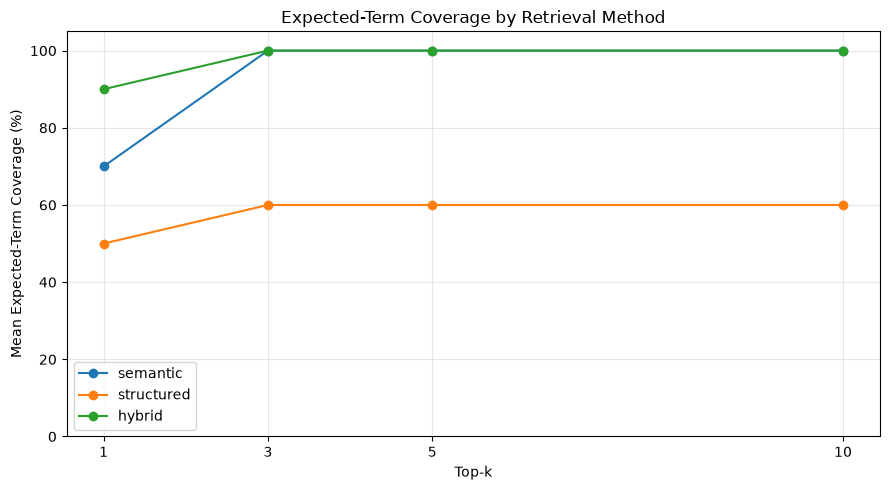

Chart saved: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_retrieval_comparison.png


In [64]:
# Cell 54
summary_df = (
    experiment_df
    .groupby(["method", "top_k"], as_index=False)
    .agg(
        mean_expected_term_coverage=("expected_term_coverage", "mean"),
        mean_result_count=("result_count", "mean"),
        questions_evaluated=("query_id", "nunique")
    )
)

summary_df["mean_expected_term_coverage_pct"] = (
    summary_df["mean_expected_term_coverage"] * 100
).round(2)

print("RETRIEVAL COMPARISON SUMMARY")
display(summary_df)

plt.figure(figsize=(9, 5))

for method_name in methods:
    method_data = summary_df[summary_df["method"] == method_name]
    plt.plot(
        method_data["top_k"],
        method_data["mean_expected_term_coverage_pct"],
        marker="o",
        label=method_name
    )

plt.title("Expected-Term Coverage by Retrieval Method")
plt.xlabel("Top-k")
plt.ylabel("Mean Expected-Term Coverage (%)")
plt.xticks(top_k_values)
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

chart_path = RESULTS_DIR / "notebook08_retrieval_comparison.png"
plt.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

In [65]:
# Cell 55
metrics_path = RESULTS_DIR / "notebook08_retrieval_experiment_metrics.csv"
details_path = RESULTS_DIR / "notebook08_retrieval_experiment_details.json"
summary_path = RESULTS_DIR / "notebook08_retrieval_experiment_summary.json"

experiment_df.to_csv(metrics_path, index=False)

with open(details_path, "w", encoding="utf-8") as file:
    json.dump(retrieval_details, file, indent=2, ensure_ascii=False, default=str)

experiment_summary = {
    "notebook": "08_feature_engineering_retrieval_optimization",
    "rag_document_count": len(rag_documents),
    "query_count": len(evaluation_queries),
    "methods_tested": list(methods.keys()),
    "top_k_values": top_k_values,
    "metric": "expected_term_coverage",
    "metric_definition": (
        "Fraction of expected query terms found in the retrieved content "
        "and metadata."
    ),
    "ground_truth_independently_verified": False,
    "formal_precision_recall_claimed": False,
    "metrics_csv": str(metrics_path),
    "details_json": str(details_path),
    "chart": str(chart_path),
    "summary": summary_df.to_dict(orient="records"),
    "limitations": [
        "Only five candidate queries were tested.",
        "Expected terms have not been independently verified as ground truth.",
        "Term coverage does not establish semantic relevance or answer correctness.",
        "No production code was modified by this experiment."
    ]
}

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(experiment_summary, file, indent=2, ensure_ascii=False, default=str)

print("RETRIEVAL EXPERIMENT ARTIFACTS SAVED")
print("Metrics:", metrics_path)
print("Detailed results:", details_path)
print("Summary:", summary_path)
print("Chart:", chart_path)

RETRIEVAL EXPERIMENT ARTIFACTS SAVED
Metrics: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_retrieval_experiment_metrics.csv
Detailed results: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_retrieval_experiment_details.json
Summary: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_retrieval_experiment_summary.json
Chart: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_retrieval_comparison.png


In [66]:
# Cell 56
import json
import pandas as pd
from pathlib import Path
from IPython.display import display

RESULTS_DIR = Path.cwd().resolve()

while not (RESULTS_DIR / "eval" / "results").exists():
    if RESULTS_DIR == RESULTS_DIR.parent:
        raise FileNotFoundError("Project root not found.")
    RESULTS_DIR = RESULTS_DIR.parent

RESULTS_DIR = RESULTS_DIR / "eval" / "results"

metrics_path = RESULTS_DIR / "notebook08_retrieval_experiment_metrics.csv"
summary_path = RESULTS_DIR / "notebook08_retrieval_experiment_summary.json"

metrics = pd.read_csv(metrics_path)

print("RETRIEVAL COMPARISON METRICS")
display(metrics)

with open(summary_path, "r", encoding="utf-8") as file:
    summary = json.load(file)

print("\nEXPERIMENT SUMMARY")
print(json.dumps(summary, indent=2, ensure_ascii=False))

RETRIEVAL COMPARISON METRICS


,query_id,query,method,top_k,result_count,expected_term_count,matched_term_count,expected_term_coverage
0,Q01,Which component consumes BatteryTemperature?,semantic,1,1,2,2,1.0
1,Q01,Which component consumes BatteryTemperature?,semantic,3,3,2,2,1.0
2,Q01,Which component consumes BatteryTemperature?,semantic,5,5,2,2,1.0
3,Q01,Which component consumes BatteryTemperature?,semantic,10,10,2,2,1.0
4,Q01,Which component consumes BatteryTemperature?,structured,1,1,2,2,1.0
5,Q01,Which component consumes BatteryTemperature?,structured,3,2,2,2,1.0
6,Q01,Which component consumes BatteryTemperature?,structured,5,2,2,2,1.0
7,Q01,Which component consumes BatteryTemperature?,structured,10,2,2,2,1.0
8,Q01,Which component consumes BatteryTemperature?,hybrid,1,1,2,2,1.0
9,Q01,Which component consumes BatteryTemperature?,hybrid,3,3,2,2,1.0



EXPERIMENT SUMMARY
{
  "notebook": "08_feature_engineering_retrieval_optimization",
  "rag_document_count": 23,
  "query_count": 5,
  "methods_tested": [
    "semantic",
    "structured",
    "hybrid"
  ],
  "top_k_values": [
    1,
    3,
    5,
    10
  ],
  "metric": "expected_term_coverage",
  "metric_definition": "Fraction of expected query terms found in the retrieved content and metadata.",
  "ground_truth_independently_verified": false,
  "formal_precision_recall_claimed": false,
  "metrics_csv": "C:\\Users\\preet\\OneDrive\\Desktop\\autosar_hld_assistant\\eval\\results\\notebook08_retrieval_experiment_metrics.csv",
  "details_json": "C:\\Users\\preet\\OneDrive\\Desktop\\autosar_hld_assistant\\eval\\results\\notebook08_retrieval_experiment_details.json",
  "chart": "C:\\Users\\preet\\OneDrive\\Desktop\\autosar_hld_assistant\\eval\\results\\notebook08_retrieval_comparison.png",
  "summary": [
    {
      "method": "hybrid",
      "top_k": 1,
      "mean_expected_term_coverage":

In [67]:

# Cell 57
import pandas as pd
from pathlib import Path

project_root = Path.cwd().resolve()

while not (project_root / "eval" / "results").exists():
    if project_root == project_root.parent:
        raise FileNotFoundError("Project root not found.")
    project_root = project_root.parent

metrics_path = (
    project_root
    / "eval"
    / "results"
    / "notebook08_retrieval_experiment_metrics.csv"
)

df = pd.read_csv(metrics_path)

summary = (
    df.groupby(["method", "top_k"], as_index=False)
      .agg(
          mean_coverage=("expected_term_coverage", "mean"),
          mean_result_count=("result_count", "mean")
      )
)

summary["mean_coverage_percent"] = (
    summary["mean_coverage"] * 100
).round(2)

print("RETRIEVAL CONFIGURATION SUMMARY")
display(summary)

best = summary.sort_values(
    ["mean_coverage", "mean_result_count"],
    ascending=[False, True]
).iloc[0]

print("\nBest configuration by coverage, then fewer results:")
print("Method:", best["method"])
print("Top-k:", int(best["top_k"]))
print("Mean expected-term coverage:", best["mean_coverage_percent"], "%")

output_path = (
    project_root
    / "eval"
    / "results"
    / "notebook08_retrieval_configuration_summary.csv"
)

summary.to_csv(output_path, index=False)
print("\nSaved:", output_path)


RETRIEVAL CONFIGURATION SUMMARY


,method,top_k,mean_coverage,mean_result_count,mean_coverage_percent
0,hybrid,1,0.9,1.0,90.0
1,hybrid,3,1.0,3.0,100.0
2,hybrid,5,1.0,5.0,100.0
3,hybrid,10,1.0,10.0,100.0
4,semantic,1,0.7,1.0,70.0
5,semantic,3,1.0,3.0,100.0
6,semantic,5,1.0,5.0,100.0
7,semantic,10,1.0,10.0,100.0
8,structured,1,0.5,0.6,50.0
9,structured,3,0.6,1.4,60.0



Best configuration by coverage, then fewer results:
Method: hybrid
Top-k: 3
Mean expected-term coverage: 100.0 %

Saved: C:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook08_retrieval_configuration_summary.csv
